# TP2 - Parte 1: dataset y preprocesamiento

Notebook de documentación y tratamiento del dataset **70 Dog Breeds Image Dataset**: análisis
exploratorio, control de calidad, conjunto independiente de evaluación, preprocesamiento,
data augmentation y splits (ver `ENUNCIADO.md`, sección 3).

Tiene que poder leerse como un informe: celdas Markdown que explican qué se hace y por qué,
código y salidas (gráficos y tablas) **ejecutadas y guardadas**. Una notebook sin salidas
visibles se considera no entregada.

Lo que produce esta notebook lo reutilizan `2-train.ipynb` y `train_classifier`: los splits
finales (CSV/JSON con rutas y etiquetas), el conjunto independiente y el preprocesamiento
encapsulado en un módulo de `src/lib/`.

**Notebook en Google Colab (si corresponde):** <reemplazar por el link, con permiso de lectura para los docentes>

Si entregan la notebook en Colab, esta copia del repositorio funciona como notebook de referencia:
el link de arriba es obligatorio y la notebook de Colab debe estar ejecutada, con sus salidas
(ver `ENUNCIADO.md`, sección 8.2).

## Equipo
- Alumno 1 : CHIAPPE, Maximiliano - C-7542/6
- Alumno 2 : LENARDUZZI, Juan - L-3398/7

In [1]:
import sys
print(sys.executable)
print(sys.version)

c:\Users\maximiliano.chiappe\Desktop\Computer vision\tuia-dog-recognition-app\.venv\Scripts\python.exe
3.12.13 (main, Mar 10 2026, 18:15:39) [MSC v.1944 64 bit (AMD64)]


## 1. Clonar el repositorio

Solo si trabajan en Colab. Si tu fork es privado, generá un token de acceso (GitHub → Settings →
Developer settings → Personal access tokens) y usalo en la URL, o subí un zip del proyecto a Colab/Drive.

In [2]:
import sys

IN_COLAB = "google.colab" in sys.modules
print("Corriendo en Colab:", IN_COLAB)

if IN_COLAB:
    REPO_URL = "https://github.com/MaxiChiappe/tuia-dog-recognition-app.git"
    !git clone -b feature/tp2-razas-perros $REPO_URL proyecto
    %cd proyecto

Corriendo en Colab: False


## 2. Instalar dependencias

Colab ya incluye torch, torchvision, opencv, numpy, scikit-learn y matplotlib;
solo se instala lo que falta.

In [3]:
if IN_COLAB:
    !pip install -q pydantic-settings python-dotenv kagglehub albumentations onnxruntime
else:
    print("Local: las dependencias ya están instaladas en el .venv (requirements.txt)")

Local: las dependencias ya están instaladas en el .venv (requirements.txt)


## 3. Configuración del entorno

En Colab no hay PostgreSQL, por lo que se desactiva pgvector y se usa la base vectorial JSON.
La configuración se define por variables de entorno **antes** de importar `lib`.

In [4]:
import os
import sys
from pathlib import Path

os.environ["USE_PGVECTOR"] = "false"
# Ajustá acá cualquier otra variable (IMAGE_SIZE, EMBEDDING_DIM, paths, etc.)

ROOT = Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from lib.config import settings

import torch
print("dataset_path:", settings.dataset_path)
print("GPU disponible:", torch.cuda.is_available())

dataset_path: data\dataset
GPU disponible: False


## 4. Descargar el dataset

In [5]:
if IN_COLAB:
    !python scripts/download_dataset.py

for carpeta in sorted(settings.dataset_path.iterdir()):
    print(carpeta.name)

.gitkeep
dogs.csv
test
train
valid


## 5. Descripción del dataset

Usamos el **70 Dog Breeds Image Dataset** de Kaggle. Viene dividido en `train/`, `valid/` y `test/`, con una carpeta por raza, y trae un `dogs.csv` que lista cada imagen con su raza y su split.

En esta sección contamos cuántas razas hay y cuántas imágenes tiene cada split, a partir del `dogs.csv`. Las resoluciones, formatos y la calidad de las imágenes se analizan en detalle en el EDA (sección 6).

In [6]:
import pandas as pd

df = pd.read_csv(settings.dataset_path / "dogs.csv")

print("Total de imágenes:", len(df))
print("Cantidad de razas:", df["labels"].nunique())
print()
print(df["data set"].value_counts())

Total de imágenes: 9346
Cantidad de razas: 71

data set
train    7946
test      700
valid     700
Name: count, dtype: int64


El dataset tiene **9346 imágenes**: 7946 en train (85%), 700 en valid (7.5%) y 700 en test (7.5%). Valid y test tienen 700 imágenes cada uno, o sea 10 por raza, mientras que train concentra la gran mayoría.

El dataset se publica con **70 razas**, pero el CSV cuenta **71**. Esto indica que alguna raza aparece escrita de dos formas distintas. Lo investigamos en la celda siguiente.

In [7]:
razas_train = set(df[df["data set"] == "train"]["labels"])
razas_valid = set(df[df["data set"] == "valid"]["labels"])
razas_test = set(df[df["data set"] == "test"]["labels"])

print("Razas que están en valid pero no en train:", razas_valid - razas_train)
print("Razas que están en train pero no en valid:", razas_train - razas_valid)
print("Razas que están en test pero no en train:", razas_test - razas_train)

Razas que están en valid pero no en train: {'American  Spaniel'}
Razas que están en train pero no en valid: {'American Spaniel'}
Razas que están en test pero no en train: set()


La raza "American Spaniel" aparece en valid como `'American  Spaniel'`, con **doble espacio**, tanto en el CSV como en el nombre de la carpeta. Para el modelo serían dos clases distintas: las imágenes de valid de esa raza nunca podrían clasificarse bien, y la métrica de validación quedaría sesgada.

Es un problema de **calidad del etiquetado**. Lo corregimos normalizando los espacios del nombre de cada raza. La misma normalización se aplica en `load_split` (`src/lib/training.py`), que es la función que lee los splits para entrenar, así la notebook y el entrenamiento usan exactamente las mismas etiquetas.

In [8]:
def normalizar_raza(nombre):
    return " ".join(nombre.split())

df["labels"] = df["labels"].apply(normalizar_raza)

print("Cantidad de razas después de corregir:", df["labels"].nunique())

Cantidad de razas después de corregir: 70


Con las etiquetas corregidas quedan **70 razas**, que coinciden con las que publica el dataset.

Ahora revisamos el **formato** de los archivos (extensiones) y la **resolución** de las imágenes. Para la resolución alcanza con leer el encabezado de cada archivo con PIL, sin cargar la imagen completa, lo que es mucho más rápido.

In [9]:
from PIL import Image

extensiones = []
tamanios = []
modos = []
for ruta in df["filepaths"]:
    ruta_completa = settings.dataset_path / ruta
    extensiones.append(ruta_completa.suffix.lower())
    with Image.open(ruta_completa) as img:
        tamanios.append(f"{img.width}x{img.height}")
        modos.append(img.mode)

df["extension"] = extensiones
df["tamanio"] = tamanios
df["modo"] = modos

print(df["extension"].value_counts())
print()
print(df["tamanio"].value_counts())
print()
print(df["modo"].value_counts())

extension
.jpg    9346
Name: count, dtype: int64

tamanio
224x224    9346
Name: count, dtype: int64

modo
RGB    9346
Name: count, dtype: int64


Las 9346 imágenes son **JPG, 224x224, RGB**, sin excepciones.

Consecuencias:
- El dataset **ya viene redimensionado** a 224x224 por su autor, coincidiendo con nuestro `IMAGE_SIZE`. El resize del preprocesamiento *no cambia nada* para estas imágenes.
- No conocemos la resolución ni ela relación de aspecto original: si las fotos no eran cuadradas, pudieron quedar recortadas o deformadas al llevarlas a 224x224.
- El filtro de "resolución mínima" no descarta nada, porque todas miden igual.
- En la Etapa 3 el clasificador va a recibir **recortes de YOLO**, de tamaños y proporciones variables, una diferencia de dominio respecto de estas imágenes cuadradas que tenemos en cuenta al evaluar sobre el conjunto independiente.

Licencia del dataset: ver sección 13.

**Limitaciones del dataset:**
- **Sesgo de origen**: las imágenes vienen de búsquedas en internet, favoreciendo fotos "de catálogo": buena iluminación, un perro bien encuadrado y centrado, sin el ruido visual de una foto real (gente, otros animales, fondos desordenados). Esto lo vamos a contrastar más adelante con el conjunto independiente (sección 8).
- **Razas muy similares entre sí**: hay pares de razas visualmente muy parecidos (mismo color, mismo tipo de pelaje), que vamos a identificar en el EDA (sección 6.2) y que van a limitar la accuracy máxima alcanzable en esas clases.
- **Ausencia de perros mestizos**: el dataset solo contempla razas puras, así que el sistema no está preparado para clasificar perros de raza mixta, algo muy común en la realidad.
- **Posibles etiquetas dudosas**: no se puede descartar que haya imágenes mal etiquetadas, algo que vamos a revisar en el control de calidad (sección 7).

## 6. Análisis exploratorio (EDA)

### 6.1 Distribución de clases

Contamos cuántas imágenes tiene cada raza en cada split, para ver si el dataset está **desbalanceado** (razas con muchas más imágenes que otras) y si valid y test tienen suficientes imágenes por raza como para calcular métricas confiables por raza.

INFO:matplotlib.font_manager:generated new fontManager


data set  test  train  valid
count     70.0   70.0   70.0
mean      10.0  113.5   10.0
std        0.0   24.7    0.0
min       10.0   65.0   10.0
25%       10.0   99.0   10.0
50%       10.0  111.5   10.0
75%       10.0  125.0   10.0
max       10.0  198.0   10.0


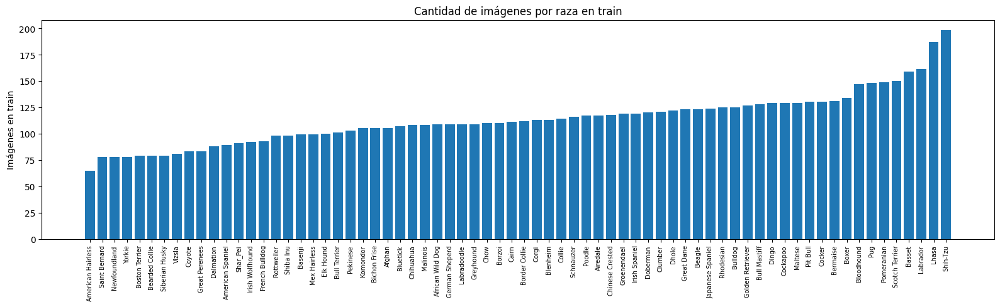

In [10]:
import matplotlib.pyplot as plt

conteo = df.groupby(["labels", "data set"]).size().unstack()
print(conteo.describe().round(1))

conteo_train = conteo["train"].sort_values()

plt.figure(figsize=(16, 5))
plt.bar(conteo_train.index, conteo_train.values)
plt.xticks(rotation=90, fontsize=7)
plt.ylabel("Imágenes en train")
plt.title("Cantidad de imágenes por raza en train")
plt.tight_layout()
plt.show()

Train tiene en promedio 113.5 imágenes por raza (mediana 111.15, desvío 24.7): desde 65 en American Hairless hasta 198 en Shih-Tzu, casi 3 veces más. Es un desbalance moderado — la mayoría de las razas cae entre 99 y 125 imágenes, con pocas excepciones en los extremos.

Valid y test tienen exactamente 10 imágenes por raza, parejo entre clases pero insuficiente para métricas estables por raza (cada error mueve la accuracy de esa raza 10 puntos). Por eso reportamos las métricas globales con promedio macro y tomamos los resultados por raza solo como orientativos.

Dado que el desbalance de train es moderado, no aplicamos corrección por ahora; si alguna raza con pocas imágenes rinde claramente peor en la evaluación, se puede probar class weights o weighted sampling.

### 6.2 Muestra visual

Mostramos una imagen de ejemplo de distintas razas para ver cómo están encuadradas las fotos: si el perro ocupa casi toda la imagen, qué fondos hay, si aparecen personas u otros perros.

Además mostramos **pares de razas fáciles de confundir**, porque son los casos donde esperamos más errores del clasificador:
- **Lhasa** y **Shih-Tzu**: perros chicos de pelo largo, muy parecidos.
- **Cockapoo** y **Labradoodle**: cruzas con caniche, de pelo rizado.
- **Beagle** y **Basset**: misma coloración tricolor y orejas largas.
- **Pug** y **Bull Mastiff**: hocico corto y máscara oscura en la cara.
- **Coyote** y **Dingo**: cánidos salvajes de aspecto similar.

Los dos últimos pares salieron de las primeras pruebas del buscador por similitud (Etapa 1), donde un Beagle se confundió con un Basset y un Pug con un Bull Mastiff.

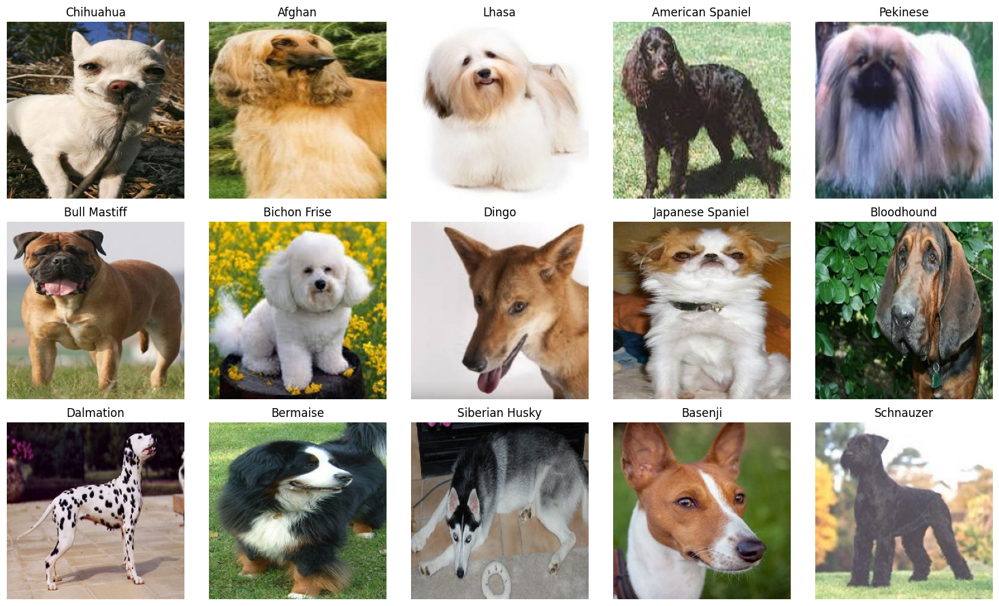

In [11]:
import cv2

train = df[df["data set"] == "train"]
razas_muestra = pd.Series(sorted(train["labels"].unique())).sample(15, random_state=42)

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
axes = axes.flatten()
for i, raza in enumerate(razas_muestra):
    ruta = train[train["labels"] == raza]["filepaths"].iloc[0]
    img = cv2.imread(str(settings.dataset_path / ruta))
    axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[i].set_title(raza)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

En la muestra se ve que las imágenes están **bien encuadradas**: un solo perro por foto, centrado, ocupando casi toda la imagen (algunas en primer plano de la cabeza, otras cortadas por los bordes). No aparecen personas ni otros perros.

Hay variedad en otros aspectos:
- **Fondos**: pasto, plantas, interiores y fondos blancos de estudio.
- **Poses**: de perfil, de frente, sentado, acostado.
- **Encuadre**: desde cuerpo entero hasta solo la cara.

Algunas imágenes se ven **deformadas** por el resize a 224x224 (el Pekinese queda estirado), consistente con que las fotos originales no eran cuadradas. También hay errores de ortografía en los nombres de las clases ("Dalmation", "Bermaise"), que mantenemos tal cual porque son los nombres de las carpetas.

**Comparación con la Etapa 3:** los recortes de YOLO también van a estar centrados en el perro, pero con otra proporción (a veces muy alargados), menor resolución y posibles oclusiones. Las imágenes del dataset son *más fáciles* que lo que va a recibir el clasificador en una escena real.

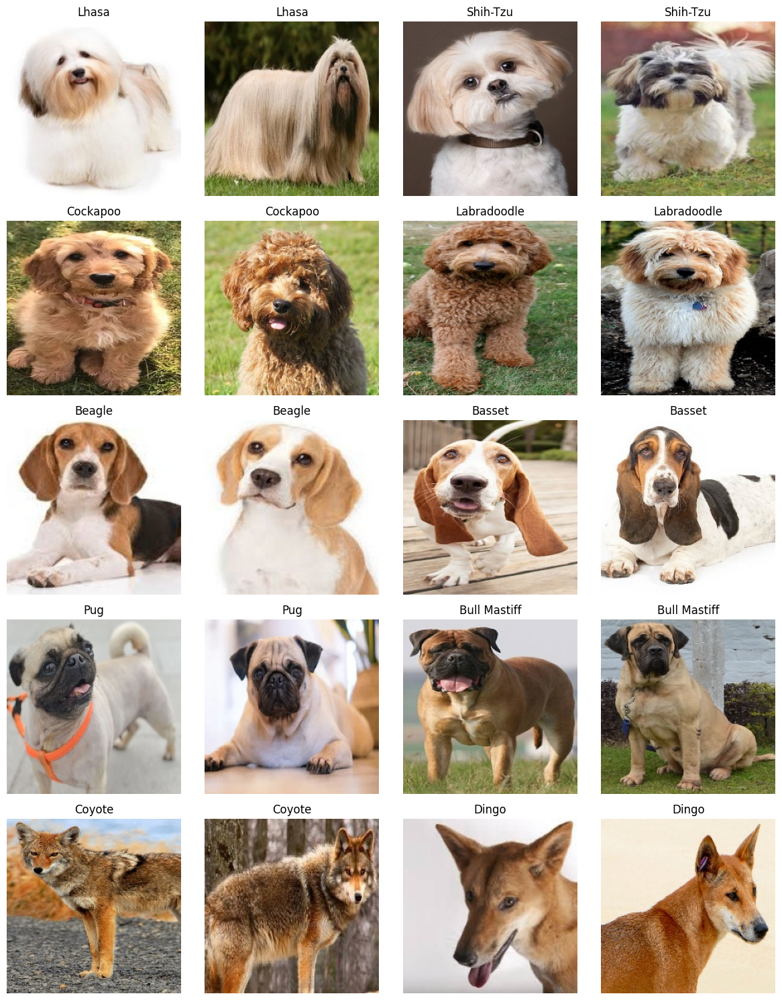

In [12]:
pares = [
    ("Lhasa", "Shih-Tzu"),
    ("Cockapoo", "Labradoodle"),
    ("Beagle", "Basset"),
    ("Pug", "Bull Mastiff"),
    ("Coyote", "Dingo"),
]

fig, axes = plt.subplots(5, 4, figsize=(12, 15))
for fila, (raza_a, raza_b) in enumerate(pares):
    rutas = list(train[train["labels"] == raza_a]["filepaths"].iloc[:2])
    rutas += list(train[train["labels"] == raza_b]["filepaths"].iloc[:2])
    nombres = [raza_a, raza_a, raza_b, raza_b]
    for col in range(4):
        img = cv2.imread(str(settings.dataset_path / rutas[col]))
        axes[fila, col].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[fila, col].set_title(nombres[col])
        axes[fila, col].axis("off")
plt.tight_layout()
plt.show()

Los pares muestran por qué algunas razas van a ser difíciles de separar:
- **Cockapoo y Labradoodle**: prácticamente indistinguibles (mismo color, pelo rizado, misma cara). El par más difícil.
- **Pug y Bull Mastiff**: comparten color y máscara negra. La diferencia real es el **tamaño**, pero sin referencia de escala esa pista se pierde en una foto.
- **Beagle y Basset**: misma coloración tricolor, se distinguen por el largo de orejas y patas, que no siempre se ve bien en un primer plano.
- **Lhasa y Shih-Tzu**: varían mucho según el corte de pelo, con más variación *dentro* de cada raza que *entre* ambas.
- **Coyote y Dingo**: el par más separable (coyote más gris y de pelaje largo, dingo más rojizo y uniforme).

La primera imagen de Lhasa parece más bien de otra raza de pelo blanco (tipo Havanese), un indicio de posibles **etiquetas dudosas** en el dataset, que tenemos en cuenta en el control de calidad.

Es esperable que los modelos confundan sobre todo estos pares, algo que verificamos con la matriz de confusión en la Notebook 2.

### 6.3 Variaciones de iluminación

Medimos el **brillo** y el **contraste** de cada imagen para ver qué tan variadas son las condiciones de iluminación:
- **Brillo**: el promedio de los píxeles de la imagen en escala de grises (0 = negro, 255 = blanco).
- **Contraste**: el desvío estándar de esos píxeles. Un valor bajo indica una imagen "chata", con poca diferencia entre zonas claras y oscuras.

Estos valores también nos sirven para definir el filtro de exposición extrema en el control de calidad (sección 7) y para elegir los rangos de brillo y contraste de la augmentation (sección 10).

       brillo  contraste
count  9346.0     9346.0
mean    125.6       58.2
std      31.2       13.3
min      27.7       16.5
25%     106.2       49.3
50%     123.8       57.8
75%     141.2       66.1
max     243.1      111.4


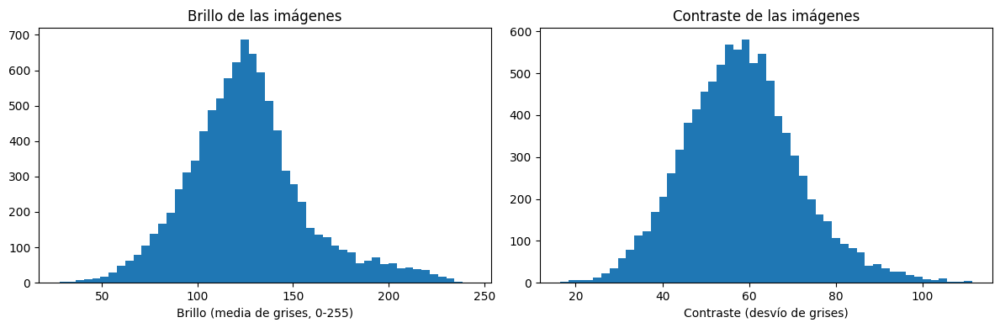

In [13]:
brillos = []
contrastes = []
for ruta in df["filepaths"]:
    gris = cv2.imread(str(settings.dataset_path / ruta), cv2.IMREAD_GRAYSCALE)
    brillos.append(gris.mean())
    contrastes.append(gris.std())

df["brillo"] = brillos
df["contraste"] = contrastes
print(df[["brillo", "contraste"]].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["brillo"], bins=50)
axes[0].set_title("Brillo de las imágenes")
axes[0].set_xlabel("Brillo (media de grises, 0-255)")
axes[1].hist(df["contraste"], bins=50)
axes[1].set_title("Contraste de las imágenes")
axes[1].set_xlabel("Contraste (desvío de grises)")
plt.tight_layout()
plt.show()

El **brillo** tiene una distribución en campana centrada en 123.8 (mediana), con la mitad de las imágenes entre 106 y 141. Hay una cola hacia la derecha (180-240) que corresponde a las fotos con **fondo blanco de estudio**. Extremos: mínimo 27.7 (muy oscura), máximo 243.1 (casi toda blanca).

El **contraste** también tiene forma de campana, centrado en 57.8 (rango 16.5-111.4). Un contraste muy bajo indica imágenes "chatas", con poca información de textura.

La iluminación del dataset es **variada pero sin muchos extremos**, esperable en fotos de internet. Para la augmentation, una variación de brillo/contraste de ±20% se mantiene dentro de este rango real. Los pocos casos extremos se revisan en el control de calidad (sección 7).

### 6.4 Cantidad de perros por imagen

Para contar cuántos perros hay en cada imagen usamos el **detector YOLO de la Etapa 3** (`detect_dogs` de `DetectionService`), con el mismo modelo y el mismo umbral de confianza que usa la app (`YOLO_CONF_THRESHOLD`).

Esto nos da dos datos:
- Cuántas imágenes tienen **más de un perro**. Son casos ambiguos para un clasificador que asume un solo perro por imagen.
- Cuántas imágenes tienen **ningún perro detectado**. Pueden ser imágenes mal etiquetadas, perros muy tapados o casos que YOLO no reconoce, como los cánidos salvajes (Coyote, Dingo, Dhole). Las revisamos en el control de calidad.

In [14]:
from lib.bootstrap import build_classifier
from lib.services.detection_service import DetectionService

detector = DetectionService(
    classifier=build_classifier(settings),
    yolo_model=str(settings.model_path / Path(settings.yolo_model).name),
    conf_threshold=settings.yolo_conf_threshold,
    dog_class_id=settings.yolo_dog_class_id,
)

cantidades = []
for ruta in df["filepaths"]:
    img = cv2.imread(str(settings.dataset_path / ruta))
    cantidades.append(len(detector.detect_dogs(img)))

df["perros_detectados"] = cantidades
print(df["perros_detectados"].value_counts().sort_index())

c:\Users\maximiliano.chiappe\Desktop\Computer vision\tuia-dog-recognition-app\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
INFO:lib.services.detection_service:Loading YOLO detector: models\yolov8n.pt


perros_detectados
0    4181
1    5071
2      90
3       4
Name: count, dtype: int64


Con la configuración de la app, YOLO **no detecta ningún perro en 4181 imágenes (45%)**, a pesar de que en todas las fotos que vimos hay un perro claramente visible.

Investigando una muestra, la causa principal es la **resolución**: YOLO agranda cada imagen a 640x640 antes de detectar (`imgsz=640`, el valor por defecto), y nuestras imágenes son de 224x224. Al estirarlas casi 3 veces quedan borrosas y el detector falla. En una muestra de 200 imágenes, los fallos bajan de 48% con `imgsz=640` a 17% con `imgsz=320`.

En la app esto no es un problema: en la Etapa 3 YOLO recibe fotos reales más grandes, donde 640 es el tamaño adecuado. Pero para contar perros en este dataset conviene usar un tamaño más cercano al real, así que repetimos el conteo con `imgsz=320`.

In [15]:
from ultralytics import YOLO

yolo = YOLO(str(settings.model_path / Path(settings.yolo_model).name))

cantidades_320 = []
for ruta in df["filepaths"]:
    img = cv2.imread(str(settings.dataset_path / ruta))
    resultado = yolo.predict(
        img,
        conf=settings.yolo_conf_threshold,
        classes=[settings.yolo_dog_class_id],
        imgsz=320,
        verbose=False,
    )[0]
    cantidades_320.append(len(resultado.boxes))

df["perros_detectados_320"] = cantidades_320
print(df["perros_detectados_320"].value_counts().sort_index())

perros_detectados_320
0    1510
1    7798
2      37
3       1
Name: count, dtype: int64


Con `imgsz=320` los resultados son mucho más razonables:

| Perros detectados | `imgsz=640` (app) | `imgsz=320` |
|---|---|---|
| 0 | 4181 (44.7%) | 1510 (16.2%) |
| 1 | 5071 | **7798 (83.4%)** |
| 2 | 90 | 37 |
| 3 | 4 | 1 |

- La gran mayoría de las imágenes tiene **un solo perro**, confirmando lo visto en las grillas.
- Las imágenes con **más de un perro** son muy pocas (38, menos del 0.5%): casos ambiguos para un clasificador de un solo perro, pero sin mayor impacto en el entrenamiento.
- Siguen quedando **1510 imágenes sin perro detectado**: en su mayoría YOLO confunde al perro con otro animal (gato, oso, caballo, oveja), sobre todo en primeros planos y razas muy peludas. Por eso *no las descartamos automáticamente*; algunas se revisan a mano en el control de calidad.

También evidencia un **cambio de dominio**: el detector, entrenado con escenas de COCO, funciona peor en estas fotos tan encuadradas que en escenas reales, que es lo que va a recibir en la Etapa 3.

## 7. Control de calidad y filtrado

Definimos reglas de filtrado explícitas y contamos cuántas imágenes descarta cada una:

1. **Archivos corruptos o ilegibles**: ya descartados de hecho, porque en la sección 5 se pudieron abrir las 9346 imágenes. Descarta 0.
2. **Resolución menor a un mínimo**: todas son 224x224, no descarta ninguna.
3. **Imágenes borrosas**: usamos la **varianza del Laplaciano** (resalta bordes; nítida = varianza alta, borrosa = varianza baja).
4. **Exposición extrema**: imágenes casi negras o casi blancas, según el brillo de la sección 6.3.
5. **Duplicados y casi-duplicados**, dentro de un split y entre splits.
6. **Imágenes sin perro visible**, revisando las que YOLO no detectó.

### 7.1 Imágenes borrosas

Calculamos la varianza del Laplaciano de cada imagen y miramos las más bajas antes de elegir un umbral.

count     9346.0
mean      1646.7
std       1896.8
min         24.8
25%        543.3
50%       1074.1
75%       2036.7
max      37153.1
Name: nitidez, dtype: float64


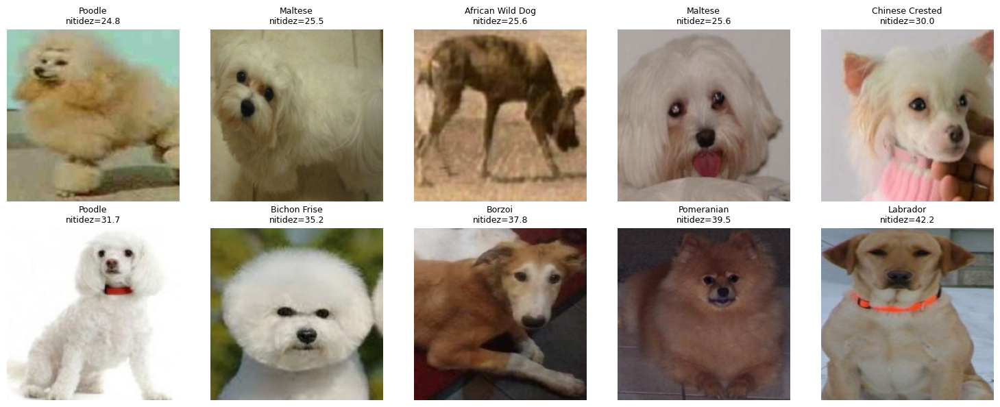

In [16]:
nitideces = []
for ruta in df["filepaths"]:
    gris = cv2.imread(str(settings.dataset_path / ruta), cv2.IMREAD_GRAYSCALE)
    nitideces.append(cv2.Laplacian(gris, cv2.CV_64F).var())

df["nitidez"] = nitideces
print(df["nitidez"].describe().round(1))

mas_borrosas = df.sort_values("nitidez").head(10)

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()
for i, (_, fila) in enumerate(mas_borrosas.iterrows()):
    img = cv2.imread(str(settings.dataset_path / fila["filepaths"]))
    axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[i].set_title(f"{fila['labels']}\nnitidez={fila['nitidez']:.1f}", fontsize=9)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

La nitidez varía muchísimo (mediana 1074, mínimo 24.8). Al mirar las 10 imágenes con menor valor, casi ninguna está realmente borrosa: la mayoría son perros **blancos o de pelo esponjoso** (Poodle, Maltese, Bichon Frise), que tienen pocos bordes marcados y por eso dan una varianza del Laplaciano baja aunque la foto esté bien.

Si usáramos un umbral alto, descartaríamos sobre todo imágenes de esas razas y les sacaríamos datos justo a ellas. Por eso elegimos un umbral **conservador: nitidez < 30**, que solo descarta las 4 imágenes más degradadas (Poodle 24.8, Maltese 25.5, African Wild Dog 25.6 y Maltese 25.6), que se ven pixeladas o con mucha compresión.

### 7.2 Exposición extrema

Miramos las imágenes más oscuras y más claras según el brillo calculado en la sección 6.3, para decidir si alguna tiene una exposición tan extrema que no se distingue el perro.

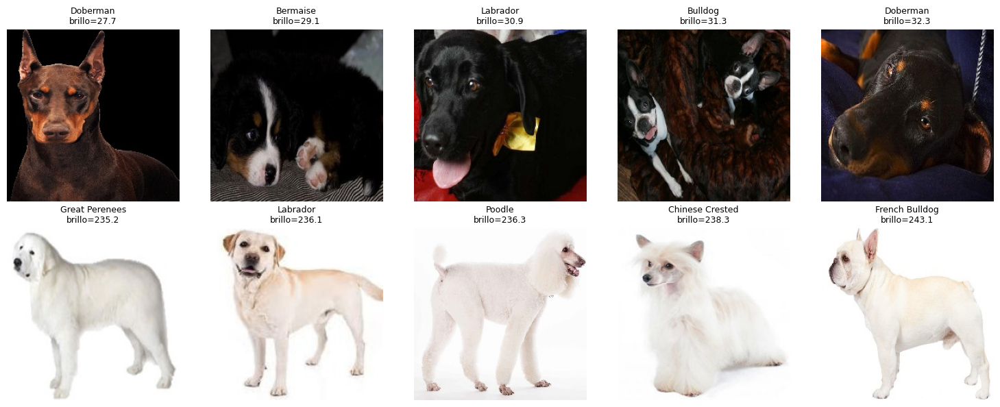

In [17]:
mas_oscuras = df.sort_values("brillo").head(5)
mas_claras = df.sort_values("brillo").tail(5)
extremas = pd.concat([mas_oscuras, mas_claras])

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()
for i, (_, fila) in enumerate(extremas.iterrows()):
    img = cv2.imread(str(settings.dataset_path / fila["filepaths"]))
    axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[i].set_title(f"{fila['labels']}\nbrillo={fila['brillo']:.1f}", fontsize=9)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

Ninguna de las imágenes extremas tiene un problema de exposición: las más oscuras son perros negros sobre fondos oscuros (Doberman, Labrador) y las más claras son perros blancos sobre fondo blanco de estudio (Great Perenees, Poodle, French Bulldog). En todas se distingue bien al perro, así que el brillo extremo refleja el color del perro y del fondo, no una mala exposición. **Esta regla no descarta ninguna imagen.**

Además, la imagen etiquetada como "Bulldog" (brillo 31.3) muestra en realidad **dos Boston Terriers**, que también es una raza del dataset. Es un ejemplo concreto de **etiqueta errónea**, una limitación del dataset que no podemos corregir revisando a mano las 9346 imágenes.

### 7.3 Duplicados y casi-duplicados

Buscamos imágenes repetidas con un **hash perceptual (dHash)**: cada imagen se reduce a 9x8 píxeles en escala de grises y se compara cada píxel con su vecino de la derecha, obteniendo una "huella" de 64 bits. Dos imágenes iguales o casi iguales (la misma foto con otra compresión o un recorte mínimo) dan la misma huella.

Nos importan especialmente los duplicados **entre splits**: si la misma imagen está en train y en test, el modelo "ya la vio" al entrenar y la métrica de test sale artificialmente alta (fuga de datos).

In [18]:
def dhash(ruta):
    gris = cv2.imread(str(ruta), cv2.IMREAD_GRAYSCALE)
    chica = cv2.resize(gris, (9, 8), interpolation=cv2.INTER_AREA)
    bits = chica[:, 1:] > chica[:, :-1]
    return "".join("1" if b else "0" for b in bits.flatten())

hashes = []
for ruta in df["filepaths"]:
    hashes.append(dhash(settings.dataset_path / ruta))
df["hash"] = hashes

duplicados = df[df.duplicated("hash", keep=False)].sort_values("hash")
splits_por_grupo = duplicados.groupby("hash")["data set"].nunique()
razas_por_grupo = duplicados.groupby("hash")["labels"].nunique()

print("Imágenes que tienen al menos un duplicado:", len(duplicados))
print("Grupos de duplicados:", duplicados["hash"].nunique())
print("Grupos con imágenes en más de un split (fuga):", (splits_por_grupo > 1).sum())
print("Grupos con la misma imagen en razas distintas:", (razas_por_grupo > 1).sum())

Imágenes que tienen al menos un duplicado: 261
Grupos de duplicados: 120
Grupos con imágenes en más de un split (fuga): 69
Grupos con la misma imagen en razas distintas: 1


El hash encuentra **261 imágenes** repetidas, agrupadas en **120 grupos**. De esos grupos, **69 tienen imágenes en más de un split** (fuga de datos) y **1 tiene la misma imagen con dos razas distintas**.

Antes de descartar nada, verificamos visualmente algunos grupos para confirmar que son realmente la misma foto y no un falso positivo del hash.

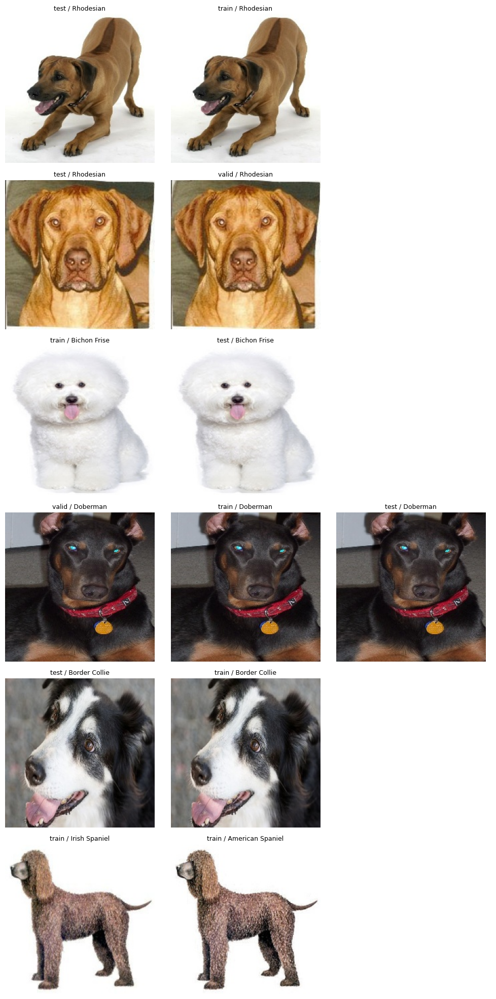

In [19]:
grupos_fuga = splits_por_grupo[splits_por_grupo > 1].index[:5]
grupo_razas = razas_por_grupo[razas_por_grupo > 1].index
grupos_a_ver = list(grupos_fuga) + list(grupo_razas)

fig, axes = plt.subplots(len(grupos_a_ver), 3, figsize=(10, 3.3 * len(grupos_a_ver)))
for fila, h in enumerate(grupos_a_ver):
    imagenes = duplicados[duplicados["hash"] == h].head(3)
    for col in range(3):
        axes[fila, col].axis("off")
        if col < len(imagenes):
            dato = imagenes.iloc[col]
            img = cv2.imread(str(settings.dataset_path / dato["filepaths"]))
            axes[fila, col].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            axes[fila, col].set_title(f"{dato['data set']} / {dato['labels']}", fontsize=9)
plt.tight_layout()
plt.show()

Todos los grupos revisados son **la misma foto exacta**, así que el hash no da falsos positivos. Hay imágenes repetidas entre test y train, entre test y valid, e incluso una misma foto de Doberman en los tres splits. Esto confirma una **fuga de datos** en los splits originales del dataset, que inflaría las métricas de test.

Esto contradice la descripción del dataset en Kaggle, donde el autor indica que eliminó los duplicados entre train, test y validación: aunque un dataset diga que está limpio, conviene verificarlo.

La última fila muestra la misma foto etiquetada como Irish Spaniel y como American Spaniel. No podemos saber cuál es la etiqueta correcta, así que descartamos las dos copias.

### 7.4 Aplicación de los filtros

Criterios:
- **Test y valid se mantienen lo más intactos posible**, porque son los conjuntos con los que medimos. Si una imagen está en train y también en valid o test, la sacamos **de train**. Si está en valid y en test, la sacamos **de valid**, así test queda completo con sus 10 imágenes por raza.
- El filtro de **nitidez** se aplica **solo a train**: queremos que test refleje las imágenes tal como llegan, incluso las de peor calidad.
- Los duplicados dentro de un mismo split se reducen a una sola copia.
- La foto con **dos razas distintas** se descarta en todas sus copias.
- Exposición extrema e imágenes sin perro detectado: **no se descarta ninguna**, por lo que vimos en las secciones 7.2 y 6.4.

In [20]:
df["motivo_descarte"] = ""

borrosa = (df["data set"] == "train") & (df["nitidez"] < 30)
df.loc[borrosa, "motivo_descarte"] = "borrosa (train)"

hashes_contradictorios = razas_por_grupo[razas_por_grupo > 1].index
contradictoria = df["hash"].isin(hashes_contradictorios) & (df["motivo_descarte"] == "")
df.loc[contradictoria, "motivo_descarte"] = "etiqueta contradictoria"

hashes_test = set(df[df["data set"] == "test"]["hash"])
hashes_valid = set(df[df["data set"] == "valid"]["hash"])

fuga_train = (df["data set"] == "train") & df["hash"].isin(hashes_test | hashes_valid) & (df["motivo_descarte"] == "")
df.loc[fuga_train, "motivo_descarte"] = "fuga: train repetida en valid/test"

fuga_valid = (df["data set"] == "valid") & df["hash"].isin(hashes_test) & (df["motivo_descarte"] == "")
df.loc[fuga_valid, "motivo_descarte"] = "fuga: valid repetida en test"

sin_motivo = df["motivo_descarte"] == ""
repetida = df[sin_motivo].duplicated(["data set", "hash"], keep="first")
df.loc[repetida[repetida].index, "motivo_descarte"] = "duplicada en el mismo split"

print("Imágenes descartadas por regla:")
print(df[df["motivo_descarte"] != ""]["motivo_descarte"].value_counts())
print()
print("Descartadas por split:")
print(df[df["motivo_descarte"] != ""]["data set"].value_counts())

df_filtrado = df[df["motivo_descarte"] == ""].copy()
print()
print("Imágenes que quedan:", len(df_filtrado), "de", len(df))

Imágenes descartadas por regla:
motivo_descarte
fuga: train repetida en valid/test    73
duplicada en el mismo split           61
fuga: valid repetida en test           6
borrosa (train)                        5
etiqueta contradictoria                2
Name: count, dtype: int64

Descartadas por split:
data set
train    136
valid      7
test       4
Name: count, dtype: int64

Imágenes que quedan: 9199 de 9346


Los filtros descartan **147 imágenes** (1.6% del dataset) y quedan **9199**:

| Regla | Descartadas |
|---|---|
| Fuga: imagen de train repetida en valid o test | 73 |
| Duplicada dentro del mismo split | 61 |
| Fuga: imagen de valid repetida en test | 6 |
| Borrosa (nitidez < 30, solo train) | 5 |
| Etiqueta contradictoria | 2 |
| Corruptas / baja resolución / exposición extrema / sin perro | 0 |

Casi todo lo descartado son **duplicados**, y la mitad de ellos generaban **fuga de datos** entre splits. Sin este filtrado, parte de las imágenes de test habrían estado también en train y las métricas habrían salido infladas.

Por split se descartan 136 de train, 7 de valid y 4 de test. Estas últimas son copias repetidas dentro del propio test: quedan algunas razas con 9 imágenes en lugar de 10, lo que no cambia la evaluación de forma importante.

## 8. Conjunto independiente de evaluación

Para medir cómo funciona el sistema con imágenes "del mundo real", armamos un conjunto con imágenes que **no pertenecen al dataset de Kaggle**, tomadas de dos datasets públicos:
- **Oxford-IIIT Pet**: fotos de perros de 14 razas que coinciden con las nuestras, más **gatos** como imágenes sin perros.
- **Stanford Dogs**: 7 razas más y **escenas con varios perros**, elegidas usando las anotaciones del dataset, que indican cuántos perros hay en cada foto.

El conjunto se arma con `scripts/build_independent_set.py`, con semilla fija, así es reproducible. Queda en `data/dataset/independent/`, con una carpeta por raza más `_escenas/` (Etapa 3) y `_sin_perro/` (falsos positivos del detector). La fuente y la licencia de cada imagen quedan en `fuentes.csv`.

Estas fotos tienen tamaños y proporciones variados, fondos complejos y a veces personas: son más parecidas a lo que recibiría la app que las imágenes de Kaggle, todas de 224x224 y bien encuadradas.

**Limitación:** las imágenes de Stanford Dogs vienen de **ImageNet**, el mismo dataset con el que se preentrenaron los modelos de torchvision. Es posible que el modelo preentrenado ya haya visto algunas de esas fotos, lo que podría mejorar un poco sus resultados en esas razas.

Verificamos con el mismo hash de la sección 7.3 que ninguna imagen del conjunto independiente esté repetida en el dataset de Kaggle.

In [24]:
ruta_independiente = settings.dataset_path / "independent"
independiente = pd.read_csv(ruta_independiente / "fuentes.csv")

print("Imágenes por tipo:")
print(independiente["tipo"].value_counts())
print()
limpias = independiente[independiente["tipo"] == "limpia"]
print("Razas en las imágenes limpias:", limpias["raza"].nunique())
print(limpias.groupby("raza").size().to_string())

hashes_independiente = []
for archivo in independiente["archivo"]:
    hashes_independiente.append(dhash(ruta_independiente / archivo))
independiente["hash"] = hashes_independiente

repetidas = independiente[independiente["hash"].isin(set(df["hash"]))]
print()
print("Imágenes del conjunto independiente repetidas en el dataset de Kaggle:", len(repetidas))

Imágenes por tipo:
tipo
limpia       126
escena        12
sin_perro     10
Name: count, dtype: int64

Razas en las imágenes limpias: 21
raza
Basset              6
Beagle              6
Border Collie       6
Boxer               6
Chihuahua           6
Doberman            6
German Sheperd      6
Golden Retriever    6
Great Perenees      6
Japanese Spaniel    6
Labrador            6
Newfoundland        6
Pit Bull            6
Pomeranian          6
Pug                 6
Rottweiler          6
Saint Bernard       6
Scotch Terrier      6
Shiba Inu           6
Siberian Husky      6
Yorkie              6

Imágenes del conjunto independiente repetidas en el dataset de Kaggle: 7


El hash encuentra **7 imágenes del conjunto independiente que coinciden con imágenes del dataset de Kaggle**. Las comparamos visualmente.

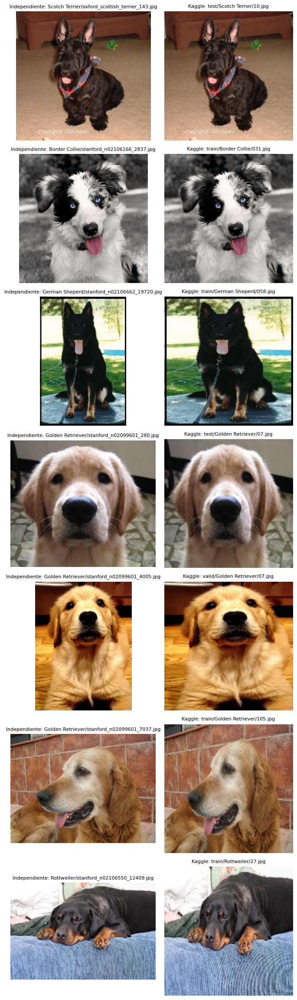

In [25]:
fig, axes = plt.subplots(len(repetidas), 2, figsize=(7, 3.3 * len(repetidas)))
for fila, (_, dato) in enumerate(repetidas.iterrows()):
    img_ind = cv2.imread(str(ruta_independiente / dato["archivo"]))
    axes[fila, 0].imshow(cv2.cvtColor(img_ind, cv2.COLOR_BGR2RGB))
    axes[fila, 0].set_title(f"Independiente: {dato['archivo']}", fontsize=8)

    igual = df[df["hash"] == dato["hash"]].iloc[0]
    img_kaggle = cv2.imread(str(settings.dataset_path / igual["filepaths"]))
    axes[fila, 1].imshow(cv2.cvtColor(img_kaggle, cv2.COLOR_BGR2RGB))
    axes[fila, 1].set_title(f"Kaggle: {igual['filepaths']}", fontsize=8)

    axes[fila, 0].axis("off")
    axes[fila, 1].axis("off")
plt.tight_layout()
plt.show()

Las 7 coincidencias son **la misma foto**: a la izquierda la original del conjunto independiente y a la derecha la versión de Kaggle, llevada a 224x224. Tiene sentido, porque el dataset de Kaggle se armó con búsquedas en internet y algunas fotos coinciden con las de Oxford-IIIT Pet y Stanford Dogs. Varias están en el test o el valid de Kaggle, y otras en train. Si las dejáramos, el modelo habría "visto" esas fotos al entrenar y la evaluación sobre el conjunto independiente saldría inflada. **Las eliminamos del conjunto independiente.**

La comparación también confirma lo que supusimos en la sección 5: el autor de Kaggle **deformó las imágenes al llevarlas a 224x224**. Por ejemplo, el German Sheperd y el Rottweiler se ven estirados en Kaggle respecto de la foto original.

In [26]:
for archivo in repetidas["archivo"]:
    (ruta_independiente / archivo).unlink()

independiente = independiente[~independiente["hash"].isin(set(df["hash"]))]
independiente.drop(columns="hash").to_csv(ruta_independiente / "fuentes.csv", index=False)

limpias = independiente[independiente["tipo"] == "limpia"]
print("Imágenes que quedan en el conjunto independiente:", len(independiente))
print(independiente["tipo"].value_counts())
print()
print("Razas en las imágenes limpias:", limpias["raza"].nunique())
print("Imágenes por raza (mínimo y máximo):", limpias.groupby("raza").size().min(), limpias.groupby("raza").size().max())

Imágenes que quedan en el conjunto independiente: 141
tipo
limpia       119
escena        12
sin_perro     10
Name: count, dtype: int64

Razas en las imágenes limpias: 21
Imágenes por raza (mínimo y máximo): 3 6


Después de eliminar las coincidencias, el conjunto independiente queda con **141 imágenes**: **119 limpias de 21 razas** (entre 3 y 6 por raza; Golden Retriever es la que menos tiene), **12 escenas con varios perros** y **10 imágenes sin perros** (gatos). Supera la referencia del enunciado de 100 imágenes y 20 razas.

Con tan pocas imágenes por raza, las métricas sobre este conjunto se interpretan de forma global, no por raza.

Mostramos ejemplos de los tres tipos de imágenes del conjunto independiente.

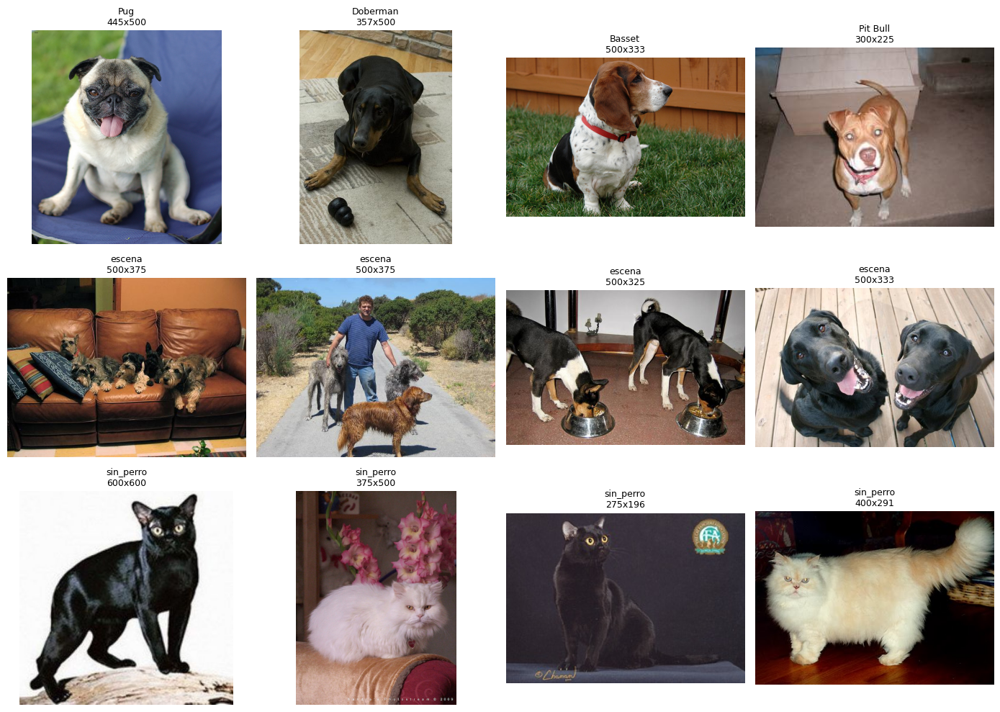

In [27]:
ejemplos = pd.concat([
    independiente[independiente["tipo"] == "limpia"].sample(4, random_state=42),
    independiente[independiente["tipo"] == "escena"].sample(4, random_state=42),
    independiente[independiente["tipo"] == "sin_perro"].sample(4, random_state=42),
])

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()
for i, (_, dato) in enumerate(ejemplos.iterrows()):
    img = cv2.imread(str(ruta_independiente / dato["archivo"]))
    axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    titulo = dato["raza"] if dato["tipo"] == "limpia" else dato["tipo"]
    axes[i].set_title(f"{titulo}\n{img.shape[1]}x{img.shape[0]}", fontsize=9)
    axes[i].axis("off")
plt.tight_layout()
plt.show()

Las imágenes del conjunto independiente son bastante distintas a las de Kaggle:
- **Tamaños y proporciones variados** (de 275x196 a 600x600, horizontales y verticales), en lugar de 224x224 fijo.
- **Más contexto**: el perro no siempre ocupa toda la foto y hay más fondo.
- **Escenas reales para la Etapa 3**: cuatro Schnauzers en un sillón, perros de distintas razas junto a una persona, dos perros comiendo o dos Labradores juntos. Incluyen perros superpuestos y de distintos tamaños.
- **Gatos negros y blancos de pelo largo**, que pueden parecerse a algunas razas de perros chicos: son una buena prueba para los falsos positivos del detector.

En una de las escenas aparece una persona identificable. Siguiendo el criterio de la sección 13, esas imágenes se usan solo para evaluar el sistema y no se publican.

**Link para los docentes:** https://drive.google.com/drive/folders/15gcmPbUfTUqzgQ1kacKKCoGZUJj_8q2N?usp=sharing

## 9. Preprocesamiento

El preprocesamiento está encapsulado en la función `preprocess_bgr` de `src/lib/preprocessing.py`, usada tanto por las notebooks como por los servicios de la app (Etapas 1, 2 y 3), así entrenamiento e inferencia preparan las imágenes exactamente igual.

Pasos y justificación:
1. **BGR → RGB**: OpenCV entrega BGR, mientras que los modelos preentrenados de torchvision esperan RGB.
2. **Resize directo a 224x224** (`IMAGE_SIZE`): no cambia nada para las imágenes del dataset (ya son 224x224). Para los recortes de YOLO, a veces muy alargados, preferimos el resize directo al *center crop* (podría cortar al perro) y al *padding* (agregaría bordes nunca vistos en el entrenamiento).
3. **Escala a [0, 1] y normalización con media/desvío de ImageNet**: misma normalización usada para entrenar los modelos preentrenados, y también para la CNN propia, así hay un único pipeline en toda la app.
4. **HWC → CHW y dimensión de batch**: PyTorch espera tensores (batch, canales, alto, ancho).

Forma del tensor: (1, 3, 224, 224)
Mínimo y máximo: -2.03 2.25


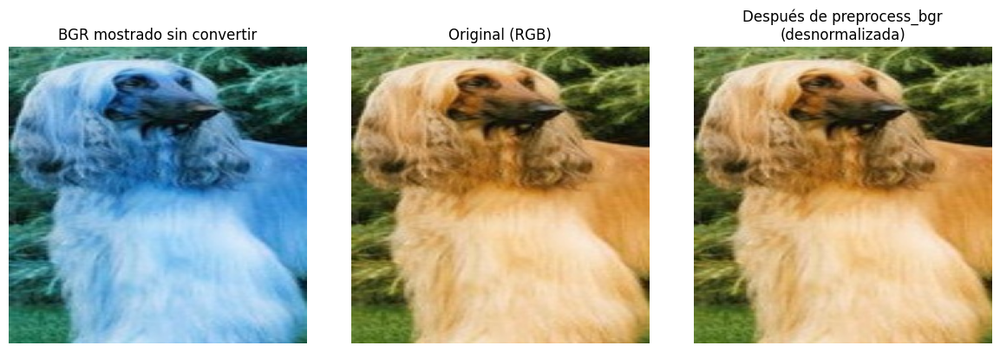

In [21]:
from lib.preprocessing import preprocess_bgr, IMAGENET_MEAN, IMAGENET_STD

ruta = settings.dataset_path / df_filtrado["filepaths"].iloc[0]
img_bgr = cv2.imread(str(ruta))
tensor = preprocess_bgr(img_bgr, settings.image_size)

print("Forma del tensor:", tuple(tensor.shape))
print("Mínimo y máximo:", round(tensor.min().item(), 2), round(tensor.max().item(), 2))

reconstruida = tensor[0].numpy().transpose(1, 2, 0) * IMAGENET_STD + IMAGENET_MEAN

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img_bgr)
axes[0].set_title("BGR mostrado sin convertir")
axes[1].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
axes[1].set_title("Original (RGB)")
axes[2].imshow(reconstruida.clip(0, 1))
axes[2].set_title("Después de preprocess_bgr\n(desnormalizada)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

El tensor tiene la forma esperada, **(1, 3, 224, 224)**: una imagen, 3 canales, 224x224. Los valores van de -2.03 a 2.25 porque, después de la normalización con ImageNet, cada canal queda centrado en 0 con desvío cercano a 1. Ya no son píxeles de 0 a 255.

La comparación visual muestra por qué importa el orden de canales: la imagen BGR mostrada sin convertir tiene los colores invertidos (el perro dorado se ve azul). Si se le pasara así al modelo, vería colores que nunca vio al entrenar. La imagen que sale de `preprocess_bgr`, desnormalizada, es idéntica a la original: el pipeline convierte bien de BGR a RGB y la normalización es reversible.

## 10. Data augmentation

La augmentation está en `build_train_augmentation` (`src/lib/preprocessing.py`) y se aplica **solo sobre train**, nunca sobre valid, test ni el conjunto independiente. Se aplica sobre la imagen BGR, antes de `preprocess_bgr`.

| Transformación | Rango | Probabilidad | Justificación |
|---|---|---|---|
| Flip horizontal | — | 0.5 | Un perro mirando a la izquierda o a la derecha es la misma raza |
| Rotación | ±15° | 0.5 | Fotos levemente inclinadas, como pasa con fotos sacadas con el celular |
| Blur gaussiano | kernel 3 a 5 | 0.2 | Fotos algo desenfocadas o recortes de YOLO de perros lejanos, de baja resolución |
| Brillo y contraste | ±20% | 0.5 | Distintas condiciones de luz. Según la sección 6.3, ±20% mantiene las imágenes dentro del rango real del dataset |
| Ruido gaussiano | desvío 0.02 a 0.06 | 0.2 | Fotos con ruido de cámara o mucha compresión |

**Evitamos** el flip vertical (un perro patas arriba no es una foto realista), las rotaciones de 90° y los cambios de color fuertes, que alterarían el color del pelaje, un rasgo clave para distinguir razas.

La rotación rellena los bordes reflejando la imagen, para no agregar esquinas negras que el modelo nunca vería en una foto real. La augmentation tiene una semilla fija (`TRAIN_SEED`) para que el entrenamiento sea reproducible. **No la usamos para corregir el desbalance**: como vimos en la sección 6.1, el desbalance de train es moderado.

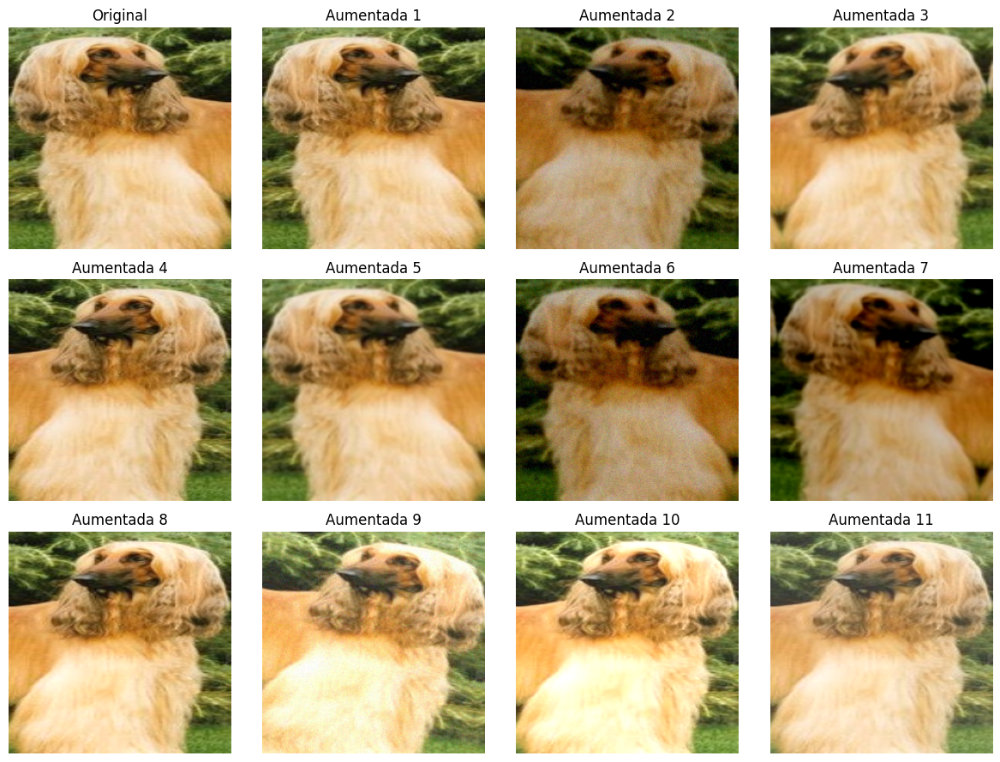

In [22]:
from lib.preprocessing import build_train_augmentation

augmentation = build_train_augmentation(seed=42)
img_bgr = cv2.imread(str(settings.dataset_path / df_filtrado["filepaths"].iloc[0]))

fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.flatten()
axes[0].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original")
for i in range(1, 12):
    aumentada = augmentation(image=img_bgr)["image"]
    axes[i].imshow(cv2.cvtColor(aumentada, cv2.COLOR_BGR2RGB))
    axes[i].set_title(f"Aumentada {i}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

En la grilla se ven las distintas transformaciones, solas o combinadas: imágenes espejadas (3, 4 y 7), levemente rotadas (2, 8 y 9), más claras (9 y 10) o más oscuras (6), y con algo de blur o ruido (2, 5 y 6). En todas el perro se sigue reconociendo y el color del pelaje se mantiene, así que la raza aparente no cambia. Los bordes de las imágenes rotadas se rellenan reflejando la imagen, sin esquinas negras.

Como cada época aplica transformaciones aleatorias distintas, el modelo nunca ve exactamente la misma imagen dos veces. Eso ayuda a reducir el overfitting.

## 11. Splits

**Mantenemos los splits originales del dataset**, ya filtrados en la sección 7. Motivos:
- Test y valid están **balanceados**, con 10 imágenes por raza, lo que permite comparar razas en igualdad de condiciones.
- Son los splits de referencia del dataset, así que los resultados son comparables con otros trabajos que lo usan.
- Con el filtrado ya eliminamos el problema que tenían: la **fuga de datos** por imágenes repetidas.

Las proporciones quedan en torno a 85% train, 7.5% valid y 7.5% test. Como no hacemos ninguna división al azar, los splits son totalmente reproducibles.

En la Etapa 1, train es la **galería** que se indexa en la base vectorial, y test más el conjunto independiente son las **consultas**: ninguna imagen de consulta está en la galería.

Verificamos que no quede ninguna imagen repetida entre splits y guardamos el resultado en `data/splits.csv`, con el mismo formato que el `dogs.csv` original (`filepaths`, `labels`, `data set`). Es el archivo que lee `train_classifier` (variable `SPLITS_FILE`) y que usa la Notebook 2.

In [23]:
splits_por_hash = df_filtrado.groupby("hash")["data set"].nunique()
print("Imágenes repetidas entre splits:", (splits_por_hash > 1).sum())
print("Imágenes repetidas dentro de un split:", df_filtrado.duplicated(["data set", "hash"]).sum())

splits = df_filtrado[["filepaths", "labels", "data set"]]
ruta_splits = Path("data") / "splits.csv"
splits.to_csv(ruta_splits, index=False)

print()
print("Splits guardados en", ruta_splits, "con", len(splits), "imágenes")
print(splits["data set"].value_counts())

Imágenes repetidas entre splits: 0
Imágenes repetidas dentro de un split: 0

Splits guardados en data\splits.csv con 9199 imágenes
data set
train    7810
test      696
valid     693
Name: count, dtype: int64


La verificación confirma que **no queda ninguna imagen repetida**, ni entre splits ni dentro de un mismo split: los splits finales no tienen fuga de datos.

| Split | Imágenes | Proporción |
|---|---|---|
| train | 7810 | 84.9% |
| valid | 693 | 7.5% |
| test | 696 | 7.6% |
| **Total** | **9199** | |

Las proporciones prácticamente no cambian respecto del dataset original. Los splits quedan guardados en `data/splits.csv`, que se versiona en el repositorio (solo tiene rutas y etiquetas, no imágenes) para que `train_classifier` y la Notebook 2 usen exactamente los mismos datos.

## 12. Resumen final

Tabla con la cantidad de imágenes y razas de cada conjunto, después del filtrado.

In [28]:
filas = []
for split in ["train", "valid", "test"]:
    datos = splits[splits["data set"] == split]
    filas.append({"Conjunto": split, "Imágenes": len(datos), "Razas": datos["labels"].nunique()})

for tipo in ["limpia", "escena", "sin_perro"]:
    datos = independiente[independiente["tipo"] == tipo]
    if tipo == "limpia":
        razas = datos["raza"].nunique()
    else:
        razas = "-"
    filas.append({"Conjunto": f"independiente ({tipo})", "Imágenes": len(datos), "Razas": razas})

resumen = pd.DataFrame(filas)
print(resumen.to_string(index=False))

                 Conjunto  Imágenes Razas
                    train      7810    70
                    valid       693    70
                     test       696    70
   independiente (limpia)       119    21
   independiente (escena)        12     -
independiente (sin_perro)        10     -


| Conjunto | Imágenes | Razas |
|---|---|---|
| train | 7810 | 70 |
| valid | 693 | 70 |
| test | 696 | 70 |
| independiente: limpias (Etapas 1 y 2) | 119 | 21 |
| independiente: escenas con varios perros (Etapa 3) | 12 | — |
| independiente: sin perros (Etapa 3) | 10 | — |

Después del control de calidad, el dataset queda con **9199 imágenes de 70 razas**, sin duplicados ni fuga entre splits, guardado en `data/splits.csv`. El conjunto independiente tiene **141 imágenes** de fuentes externas, sin coincidencias con el dataset de Kaggle.

## 13. Licencias y uso de imágenes

- **70 Dog Breeds Image Dataset (Kaggle)**: licencia **CC0: Public Domain**, sin restricciones de uso. Lo usamos con fines académicos para este trabajo práctico. Las imágenes no se suben al repositorio (`data/dataset/*` está en el `.gitignore`).
- **Conjunto independiente**:
  - Oxford-IIIT Pet Dataset (Parkhi et al., 2012): licencia **CC BY-SA 4.0**, que permite el uso comercial y de investigación. Los derechos de autor de cada imagen siguen siendo de sus dueños originales.
  - Stanford Dogs Dataset (Khosla et al., 2011): imágenes tomadas de ImageNet, de uso académico y no comercial.
  
  La fuente y la licencia de cada imagen están en `data/dataset/independent/fuentes.csv`. Las imágenes tampoco se suben al repositorio: se comparten con un link de solo lectura para los docentes.
- **Personas identificables**: no buscamos imágenes con personas. En las escenas del conjunto independiente pueden aparecer personas junto a los perros; esas imágenes se usan solo para evaluar el sistema y no se publican.